# Lab: Meso-level analysis

<a href="../downloads/lab_03.ipynb"
   class="btn btn-outline-primary"
   download>
  Download notebook (.ipynb)
</a>

## Contents

- [General notes](#General-notes)
- [PART 1: Network preprocessing](#PART-1:-Network-preprocessing)
- [PART 2: Communities](#PART-2:-Communities)
- [PART 3: Positions and roles](#PART-3:-Positions-and-roles)

## General notes

In this lab you will work on meso-level structures: components, cores, positions, roles, and communities. You will also keep practicing generating network data from the base data you received during the first week.

## PART 1: Network preprocessing

The objective of this part of the lab is to practice using components and coreness to explore the meso-level structure of a social network and for filtering. Here you can use a retweet network you already generated. The first two tasks are short and specific: a warm-up, to see that you can compute these two types of meso-level structures. They are followed by a free explorative task, where you can make your own decisions about how to use these functions and in which order.

### Task 1.1

Compute the components, print statistics about them (number, size of largest, ...), and mark the components in a node-link plot of the network (e.g. using different colours).

#### TIPS

- As for the previous lab, work on a filtered network so that the computations take a reasonable time on the machine that you are using.
- The retweet network is directed, so you can compute both weak and strong components. Compare them.

#### Student workspace

full network    : IGRAPH DNW- 755988 1518294 -- 
+ attr: name (v), weight (e)
filtered network: IGRAPH DNW- 5648 117270 -- 
+ attr: name (v), weight (e)
--- WEAK components ---
number of components    : 224
largest component       : 5424 nodes (96.0% of the network)
second largest          : 2
singletons (size 1)     : 222
non-trivial (size >= 2) : 2
10 largest sizes        : [5424, 2, 1, 1, 1, 1, 1, 1, 1, 1]
size distribution       : {5424: 1, 2: 1, 1: 222}

--- STRONG components ---
number of components    : 4060
largest component       : 1500 nodes (26.6% of the network)
second largest          : 10
singletons (size 1)     : 4011
non-trivial (size >= 2) : 49
10 largest sizes        : [1500, 10, 9, 8, 6, 5, 4, 4, 4, 4]
size distribution       : {1500: 1, 10: 1, 9: 1, 8: 1, 6: 1, 5: 1, 4: 5, 3: 3, 2: 35, 1: 4011}



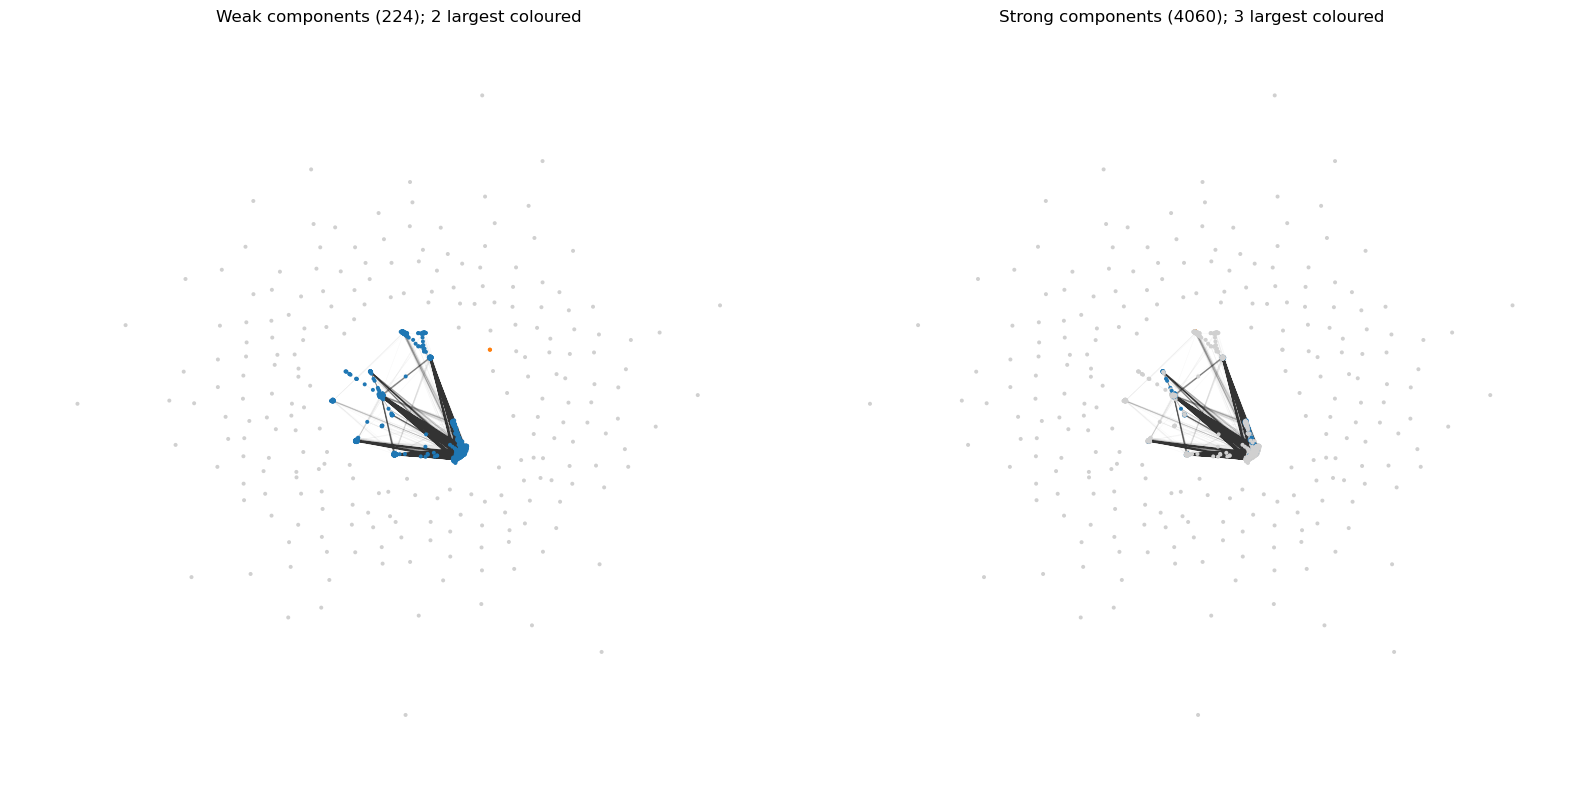

In [6]:
import random
from pathlib import Path
from collections import Counter

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex

random.seed(42)                      # reproducible layouts
DATA = Path('../data')

# load
# directed network saved in lab 2 (names = account IDs, weight = number of retweets)
g_full = ig.read(DATA / 'retweet_network.ncol', format='ncol', directed=True)
g_full.simplify(multiple=True, loops=True, combine_edges={'weight': 'sum'})   # removes self-loops
print('full network    :', g_full.summary())

# filter
# same filter as lab 2: strength = retweets sent + received.
# No giant-component step here: we want to see the small components too.
MIN_STRENGTH = 50
strength = np.array(g_full.strength(mode='all', weights='weight'))
g = g_full.induced_subgraph(np.where(strength >= MIN_STRENGTH)[0].tolist())
print('filtered network:', g.summary())

# components
weak = g.connected_components(mode='weak')
strong = g.connected_components(mode='strong')


def component_stats(cl, name):
    sizes = sorted(cl.sizes(), reverse=True)
    print(f'--- {name} components ---')
    print(f'number of components    : {len(sizes)}')
    print(f'largest component       : {sizes[0]} nodes ({sizes[0] / g.vcount():.1%} of the network)')
    print(f'second largest          : {sizes[1] if len(sizes) > 1 else 0}')
    print(f'singletons (size 1)     : {sum(s == 1 for s in sizes)}')
    print(f'non-trivial (size >= 2) : {sum(s >= 2 for s in sizes)}')
    print(f'10 largest sizes        : {sizes[:10]}')
    print(f'size distribution       : {dict(sorted(Counter(sizes).items(), reverse=True)[:10])}')
    print()


component_stats(weak, 'WEAK')
component_stats(strong, 'STRONG')

# plot
layout = g.layout_fruchterman_reingold() if g.vcount() <= 1500 else g.layout_drl()

# undirected copy only for drawing: same vertex order (so layout and colours still match),
# and no arrowheads covering the nodes
g_draw = g.as_undirected(mode='collapse')
# transparent edges, set as an edge attribute (this is what igraph's matplotlib backend respects);
# lower the 0.03 if the nodes are still hidden, raise it if the edges are invisible
g_draw.es['color'] = [(0.2, 0.2, 0.2, 0.03)] * g_draw.ecount()


def component_colors(cl, n_colored=8, other='#d0d0d0'):
    """One colour for each of the n_colored largest components, grey for all the others."""
    order = sorted(range(len(cl)), key=lambda i: -len(cl[i]))
    palette = [to_hex(c) for c in plt.get_cmap('tab10').colors]
    cmap = {comp: palette[r] for r, comp in enumerate(order[:n_colored])}
    return [cmap.get(m, other) for m in cl.membership]


fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, cl, name, n_col in [(axes[0], weak, 'Weak', 2), (axes[1], strong, 'Strong', 3)]:
    ig.plot(g_draw, target=ax, layout=layout,
            vertex_color=component_colors(cl, n_colored=n_col),
            vertex_size=4, vertex_frame_width=0, edge_width=0.4)
    ax.set_title(f'{name} components ({len(cl)}); {n_col} largest coloured')
    ax.axis('off')
plt.tight_layout()
plt.show()

#### Notes / observations


Three is one giant weak component that holds 5424/5648 accounts (96.0%). The other 224 components are one pair and 222 that are alone, which are probably active accounts whose retweet partners were removed by the strength ≥ 50 filter.

The largest strong component has only 1500 accounts (26.6%), and 4011 of the 4060 strong components are alone. Retweets rarely go both ways, so only a core of accounts can reach each other in both directions. The rest are one-directional or retweeters.

The giant weak component loses only 4% of the nodes, while the giant strong component would lose about 73%. The giant weak component is therefore the sensible one to keep.

### Task 1.2

Now compute the coreness of each node. What is the highest coreness in the network? For different values of k, highlight the nodes with coreness k or higher in a node-link plot (e.g. using colour, or a different node shape).

#### TIPS

- Look at how the network core changes varying k, e.g. if you get a single core inside the largest component, or if for some values of k you get multiple cores that are not connected to each other.

#### Student workspace

Highest coreness (all): 50
Highest coreness (in) : 5
Highest coreness (out): 6

Nodes per coreness value (all):
{0: 222, 1: 197, 2: 202, 3: 166, 4: 136, 5: 131, 6: 144, 7: 113, 8: 141, 9: 137, 10: 102, 11: 108, 12: 93, 13: 111, 14: 113, 15: 101, 16: 91, 17: 119, 18: 90, 19: 94, 20: 135, 21: 125, 22: 100, 23: 134, 24: 150, 25: 120, 26: 159, 27: 104, 28: 143, 29: 104, 30: 125, 31: 142, 32: 112, 33: 86, 34: 105, 35: 104, 36: 66, 37: 90, 38: 72, 39: 62, 40: 79, 41: 53, 42: 74, 43: 44, 44: 43, 45: 36, 46: 41, 47: 96, 48: 29, 49: 13, 50: 291}


,nodes,edges,weak components,largest component,second largest
k,,,,,
1,5426,117270,2,5424,2
2,5229,117074,1,5229,0
3,5027,116681,1,5027,0
4,4861,116192,1,4861,0
5,4725,115662,1,4725,0
6,4594,115014,1,4594,0
7,4450,114170,1,4450,0
8,4337,113385,1,4337,0
9,4196,112275,1,4196,0


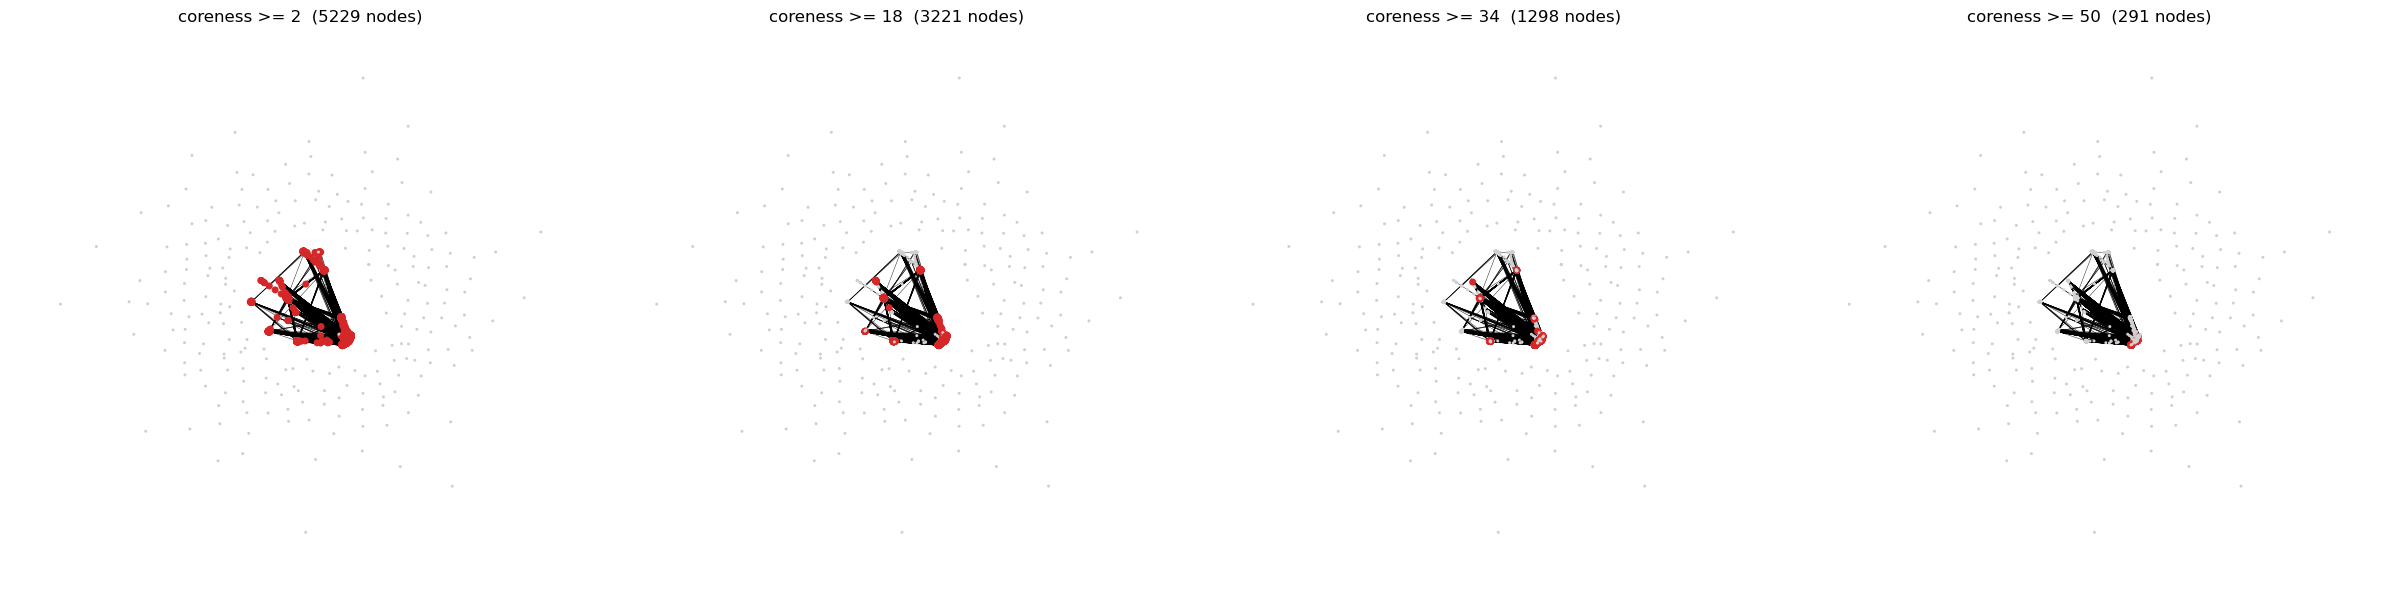

In [4]:
# coreness
# mode="all" ignores edge direction (the standard k-core);
# "in" / "out" give the directed versions (only edges received / sent count).
core_all = np.array(g.coreness(mode='all'))
core_in = np.array(g.coreness(mode='in'))
core_out = np.array(g.coreness(mode='out'))

kmax = int(core_all.max())
print(f'Highest coreness (all): {kmax}')
print(f'Highest coreness (in) : {core_in.max()}')
print(f'Highest coreness (out): {core_out.max()}')
print('\nNodes per coreness value (all):')
print(dict(sorted(Counter(core_all.tolist()).items())))


#  how does the core change with k?
def core_summary(graph, coreness, ks):
    rows = []
    for k in ks:
        sub = graph.induced_subgraph(np.where(coreness >= k)[0].tolist())
        sizes = sorted(sub.connected_components(mode='weak').sizes(), reverse=True)
        rows.append({'k': k,
                     'nodes': sub.vcount(),
                     'edges': sub.ecount(),
                     'weak components': len(sizes),
                     'largest component': sizes[0] if sizes else 0,
                     'second largest': sizes[1] if len(sizes) > 1 else 0})
    return pd.DataFrame(rows).set_index('k')


display(core_summary(g, core_all, range(1, kmax + 1)))

# plots
# values of k to highlight (replace with your own list)
KS = [2, 18, 34, 50]

fig, axes = plt.subplots(1, len(KS), figsize=(6 * len(KS), 6))
for ax, k in zip(np.atleast_1d(axes), KS):
    in_core = core_all >= k
    ig.plot(g_draw, target=ax, layout=layout,                  # g_draw and edge_col come from Task 1.1
            vertex_color=['#d62728' if x else '#d0d0d0' for x in in_core],     # red = in the k-core
            vertex_size=[7 if x else 3 for x in in_core],
            vertex_frame_width=0, edge_width=0.3, edge_color=edge_col)
    ax.set_title(f'coreness >= {k}  ({in_core.sum()} nodes)')
    ax.axis('off')
plt.tight_layout()
plt.show()

#### Notes / observations

Highest coreness is 50 (undirected), but only 5 for in and 6 for out. The dense core exists only when you count both directions together. In one direction alone, no account is in a deeply nested group. 

There is one connected core at every k. For every k from 2 to 50 the table shows 1 weak component and 0 for the second largest, so the core never splits into separate cores. Most of the structure is also in the core: at k = 11 you still have 3957 of 5648 nodes and 110108 of 117270 edges (94%). The nodes with low coreness are peripheral and have few edges.

There is a spike at k = 50. 291 accounts all have coreness 50, far more than at any neighbouring value (13 at k = 49, 96 at k = 47). They have 11062 edges, so about a quarter of all possible pairs among them are connected. That is a very tight block.

### Task 1.3

Now combine the functions to compute compements and cores, in the way(s) that you prefer, and produce a filtered network to be used in Parts 2 and 3.

#### TIPS

- Do not make a random choice: you have to motivate why you have chosen a specific way of using (or not using) these functions.
- If the network has a clear "giant component", consider generating a new graph induced by that component (but if you choose to do so, you'll have to motivate your choice).

#### Student workspace

,nodes,edges,% of filtered nodes,density,weak components
option,,,,,
A: whole filtered network,5648,117270,100.0,0.00368,224
B: giant weak component,5424,117269,96.0,0.00399,1
"C: giant component, 2-core",5229,117074,92.6,0.00428,1
"C: giant component, 3-core",5027,116681,89.0,0.00462,1
"C: giant component, 4-core",4861,116192,86.1,0.00492,1
"C: giant component, 5-core",4725,115662,83.7,0.00518,1
"C: giant component, 6-core",4594,115014,81.3,0.00545,1
"C: giant component, 7-core",4450,114170,78.8,0.00577,1
"C: giant component, 8-core",4337,113385,76.8,0.00603,1


final network: IGRAPH DNW- 5424 117269 -- 
+ attr: name (v), weight (e)
weak components: 1 | density: 0.00399


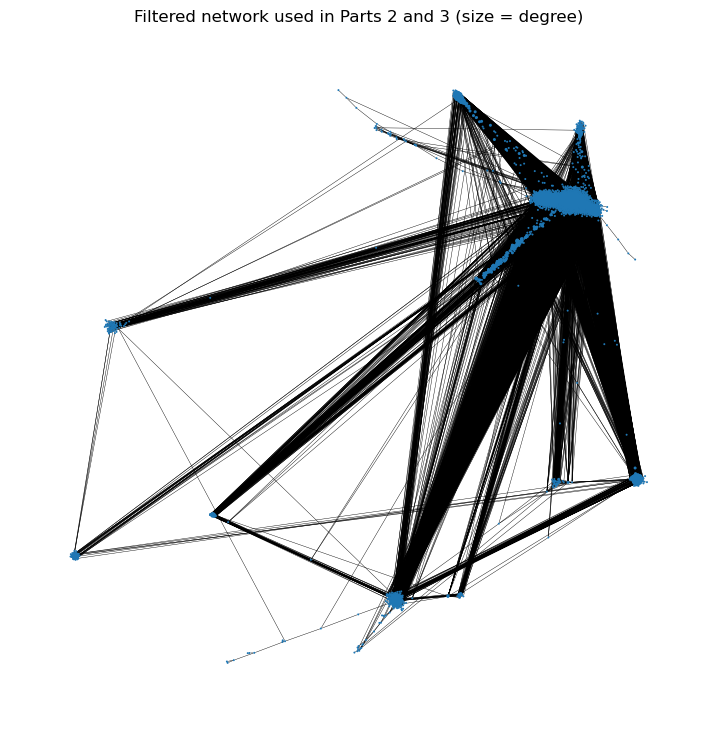

In [5]:
# candidate filters

# Coreness depends on the graph it is computed on, so inside the giant component
# it is recomputed, not reused from Task 1.2.
giant = g.connected_components(mode='weak').giant()
core_giant = np.array(giant.coreness(mode='all'))


def graph_row(label, graph):
    comps = graph.connected_components(mode='weak')
    return {'option': label,
            'nodes': graph.vcount(),
            'edges': graph.ecount(),
            '% of filtered nodes': round(100 * graph.vcount() / g.vcount(), 1),
            'density': round(graph.density(), 5),
            'weak components': len(comps)}


rows = [graph_row('A: whole filtered network', g),
        graph_row('B: giant weak component', giant)]
for k in range(2, int(core_giant.max()) + 1):
    sub = giant.induced_subgraph(np.where(core_giant >= k)[0].tolist())
    rows.append(graph_row(f'C: giant component, {k}-core', sub))
display(pd.DataFrame(rows).set_index('option'))

USE_GIANT = True     # induce the network on the giant weak component?
CORE_K = None        # None = no core filtering; e.g. 5 = additionally keep the 5-core

g_final = g
if USE_GIANT:
    g_final = g_final.connected_components(mode='weak').giant()
if CORE_K:
    cn = np.array(g_final.coreness(mode='all'))
    g_final = g_final.induced_subgraph(np.where(cn >= CORE_K)[0].tolist())
    # a k-core can fall apart into several pieces: keep the largest one
    g_final = g_final.connected_components(mode='weak').giant()

print('final network:', g_final.summary())
print('weak components:', len(g_final.connected_components(mode='weak')),
      '| density:', round(g_final.density(), 5))

# save for Parts 2 and 3
# the pickle keeps direction, account IDs (name) and weights exactly as they are
g_final.write_pickle('retweet_network_filtered.pickle')
g_final.write_graphml('retweet_network_filtered.graphml')

# plot the result
g_final_draw = g_final.as_undirected(mode='collapse')     # no arrowheads
deg = np.array(g_final_draw.degree())
fig, ax = plt.subplots(figsize=(9, 9))
ig.plot(g_final_draw, target=ax, layout=layout if g_final.vcount() == g.vcount() else g_final_draw.layout_drl(),
        vertex_color='#1f77b4', vertex_size=list(2 + 12 * np.sqrt(deg / deg.max())),
        vertex_frame_width=0, edge_width=0.3, edge_color=(0.2, 0.2, 0.2, 0.03))
ax.set_title('Filtered network used in Parts 2 and 3 (size = degree)')
ax.axis('off')
plt.show()

#### Notes / observations

We kept the giant weak component and did not apply a k-core (USE_GIANT = True, CORE_K = None). The result is 5424 accounts and 117269 edges.

The giant component loses nothing structural. It removes 224 accounts but only 1 edge out of 117270. Those accounts are disconnected from everything else, so they cannot belong to a community or bridge between groups in Parts 2 and 3.

A k-core would only remove the periphery. The k-core stays connected for every k (1 component each time), so connectivity gives no reason to filter. Higher k just removes accounts, for example the 10-core loses 28% of the nodes but only 5% of the edges. Those are mostly low-degree accounts retweeting a few hubs, and they are what determines which community a hub belongs to. The density rises with k only because the sparse periphery disappears.

The plot shows the structure we expect. A few large hubs sit at the edges and connect into one dense mass of low-degree accounts, with a few small groups attached by thin links. This is the hub-and-spoke pattern from lab 2, so Part 2 should find communities centred on these hubs.

## PART 2: Communities


### Task 2.1

Look at the community detection algorithms available on igraph, and choose (at least) three using different approaches. One of them must be modularity-based, and you should play with the resolution parameter to change the size of the discovered communities. For each algorithm and parameter setting, plot the discovered communities and compare them visually.

#### QUESTIONS

- Which community structures, among the ones you have produced using the different algorithms and settings, are more similar or dissimilar to each other?
- Which of the community structures provide the best represention for your network? Are there any results that you do not find to be appropriate descriptions of the network? Explain your reasoning.

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 2.2

Compare the different community structures you preduced in the previous task using a numerical comparison measure of your choice. Do these results align with the impression you got from the network visualisations?

#### TIPS

- We assume that you are familiar with functions to compare clusterings. If not, in addition to making the comparison using one of the methods provided by igraph, find information about the applied measure (we may ask what the measure you chose is computing when you present your results).

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 2.3

One application of community detection is to summaries a large social network. In this task, produce a new summarised graph using your selected community structure.

#### TIPS

- Use a node for each community, with a size representing the number of actors in that community.
- Use weighted edges to indicate how many edges go from one community to the other in the original network.
- Considering filtering edges using some threshold on the weights (please motivate).

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 2.4

Another application of community detection is to identify interesting communities to look at in more detail. In this task we ask you to generate two networks based on the URLs and/or domains posted by the accounts in the original data. Let us call R an entity that can be present in a tweet (R being a specific URL or a top-level domain). A co-action between accounts A and B occurs when A and B post one tweet each at no more than s seconds from each other, with the two tweets both containing the same entity R. A tie between A and B is generated if at least r co-actions have occurred between A and B. Varying the parameters above, generate two networks:

- One aimed at identifying bots. For example, using s = one second and R representing URLs. You can assume that it is unlikely for two "human-driven" accounts to independently post the same URL (e.g. http://www.lejdd.fr/Politique/Laurent-Fabius-au-JDD-Oui-j-etais-tres-emu-763913) at the same time.
- One aimed at identifying ideologically- or topically-related groups of accounts, for example groups of accounts posting the same URL(s) even though not necessarily at the same exact time.

#### TIPS & QUESTIONS:

- Think of whether you should consider or not retweets to generate this network.
- When you choose the filters (the type of entity R, the time interval s, and the number of required co-actions r), try to identify values leading to "reasonable" networks: if the resulting network is too dense, it may take too long to analyse it and (most importantly) the network structure may not be usable as a proxy to identify bots and/or ideology.
- Use the code you wrote last week, for example the one generating an overview of the network structure, to decide good parameter settings.
- Which entities are useful to define the ideology network?

**REFLECTION POINT:**  Two weeks ago you received some data with the information that you would use it to perform some social network analysis. Now you have generated various types of networks from this data - and you could keep producing many other types of derived data from it. This is quite typical in explorative studies based on secondary data. To produce the data, you have taken a number of data management decisions, such as writing an ad hoc script for each network generation task, or writing a general script converting all the information in the json file into data structures (such as Python dictionaries) and only adding specific output functions for each network, or producing intermediate data (such as CSV files, a relational database, ...) that you could then use to generate the required views. You have also made decisions about the languages to manipulate the data (All in Python? Or mostly SQL? Or have you relied on Bash commands such as AWK?) Would you make the same choices if you had to do this again?


#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 2.5

Now choose one (or just a few) communities you produced in the previous task, either representing potential bots or an ideologically-cohese group defined by co-retweeting or co-sharing: your choice, also depending on what you found in your data! Characterise some of the accounts in that community using a combination of actor-level network metrics and qualitative analysis.

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

## PART 3: Positions and roles

As you know, there are multiple types of positions and roles. In this part of the lab we use a community structure you identified during the previous part to look for positions as inter-community bridges. However, feel free to experiment with other types of positions if you have some spare time.

### Task 3.1

Identify sets of actors in the same position, where similarity is defined as: connected to nodes from the same set of communities (at least two).

#### TIPS

- There is no function doing this on igraph: you have to write your own code.
- As explained in the course theory, you can build a matrix with actors as rows, communities as columns, and values (i,j) indicating the connectivity between node i and community j. Equal rows indicate the same position.
- Your network is probably more complex that the pedagogical example used in the lecture notes. Therefore, you may have to adapt the matrix construction and/or row comparison method. If this is the case, explain your choices.
- BONUS QUESTION: while here we are clustering the rows of the matrix, it is also possible to use the matrix to look for similar columns. We will not examine you on this, but feel free to look into it if you have some spare time.

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 3.2

Pick one position containing at least two actors that you find interesting (e.g. based on the communities they bridge in the network visualisation) and qualitatively characterise those actors (or a sample of them).

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;